# Nested-record figures (no em dash) + fall-only high-chl events

**Section A** remakes the five NESTED-record tail-sensitivity figures from
`figS02_S03_S13_product-record-checks.ipynb` (AO.emp chl, adg(443), Kd(490), bbp(443)) and the
cloud-fraction one, pixel-identical except the titles contain **no em dashes** (year-range
en dashes are normalized to plain hyphens as well). Same checkpoints, same estimators,
same layout.

**Section B** adds a fall-only (DOY >= 213) high-chl event-day figure in the bar style of
`fig03_4a_6_S3_S4_re-do-figs.ipynb` Figure 1, so the significant fall increases stand on their own instead
of sharing panels with spring.

Data: the same $HOME checkpoints the source notebooks use. Nothing is
streamed; if a checkpoint is missing, that product is skipped with a message.

## A1. Imports + configuration

In [1]:
import os, pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.ticker import MultipleLocator
from scipy.stats import theilslopes, kendalltau, norm, t as tdist
warnings.filterwarnings("ignore", category=RuntimeWarning)

CKPT_DIR     = Path(os.environ.get("MODIS_CKPT_DIR", str(Path.home())))  # add your path
CUTOFF_N     = 2024          # "early" fit uses years < CUTOFF_N
CLIM_HALFWIN = 12            # DOY climatology half-window (days)
C_FULL, C_EARLY = "#d6602c", "#1f4ec7"
OUTDIR = Path.cwd() / "outputs_remakes"; OUTDIR.mkdir(exist_ok=True)

# per-product config; titles rewritten WITHOUT em dashes (colons/commas instead)
PRODUCTS_N = {
    "chl": dict(kind="log", cadence="DAY", minn=20,
                ylab="log$_{10}$ AO.emp chl anomaly",
                title="Lewis & Arrigo AO.emp chl: deseasonalized daily anomaly, NESTED records",
                line2="drawn across the full span"),
    "adg": dict(kind="log", cadence="8D", minn=20,
                ylab="log$_{10}$ adg(443) anomaly",
                title="MODIS GIOP adg(443), CDOM+detritus absorption: deseasonalized 8-day anomaly, NESTED records",
                line2="extrapolated"),
    "kd490": dict(kind="log", cadence="8D", minn=20,
                  ylab="log$_{10}$ Kd(490) anomaly",
                  title="MODIS Kd(490), diffuse attenuation: deseasonalized 8-day anomaly, NESTED records",
                  line2="extrapolated"),
    "bbp": dict(kind="log", cadence="MO", minn=8,
                ylab="log$_{10}$ bbp(443) anomaly",
                title="MODIS GIOP bbp(443), particulate backscatter: deseasonalized monthly anomaly, NESTED records",
                line2="extrapolated"),
    "cloudfrac": dict(kind="lin", cadence="DAY", minn=20, unit="%-pt",
                      ylab="MODIS cloud fraction anomaly (%-pt)",
                      title="MODIS cloud fraction: deseasonalized daily anomaly, NESTED records",
                      line2="extrapolated"),
}
REGION = "Full DBO region"
print("config ok | checkpoints from", CKPT_DIR)

config ok | checkpoints from ~


## A2. Trend + deseasonalization helpers

Verbatim ports from the trend-split notebook: circular-DOY (or month-of-year) climatology,
Theil-Sen + AR(1)-adjusted Mann-Kendall, and the AR(1)-inflated CI band on the fitted line.

In [2]:
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def _stx(p):
    if not np.isfinite(p): return "n/a"
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"

def deseasonalize_log10(da, cadence):
    raw = np.asarray(da.values, float).copy(); raw[~np.isfinite(raw) | (raw <= 0)] = np.nan
    y = np.log10(raw); t = pd.to_datetime(da["time"].values)
    if cadence == "MO":                                        # month-of-year climatology
        mo = np.asarray(t.month, int); clim = np.full(13, np.nan)
        for m in range(1, 13):
            v = (mo == m) & np.isfinite(y)
            if v.sum() >= 5: clim[m] = np.nanmean(y[v])
        anom = y - clim[mo]
    else:                                                      # 8D / DAY: circular DOY climatology
        doy = np.asarray(t.dayofyear, int); clim = np.full(367, np.nan)
        for d in range(1, 367):
            dd = np.abs(doy - d); dd = np.minimum(dd, 366 - dd)
            m = (dd <= CLIM_HALFWIN) & np.isfinite(y)
            if m.sum() >= 5: clim[d] = np.nanmean(y[m])
        anom = y - clim[doy]
    dec = np.asarray(t.year + (np.asarray(t.dayofyear) - 1) / 365.25, float)
    return t, dec, anom

def deseasonalize_linear(da):
    y = np.asarray(da.values, float).copy(); y[~np.isfinite(y)] = np.nan
    t = pd.to_datetime(da["time"].values)
    doy = np.asarray(t.dayofyear, int); clim = np.full(367, np.nan)
    for d in range(1, 367):
        dd = np.abs(doy - d); dd = np.minimum(dd, 366 - dd)
        m = (dd <= CLIM_HALFWIN) & np.isfinite(y)
        if m.sum() >= 5: clim[d] = np.nanmean(y[m])
    dec = np.asarray(t.year + (doy - 1) / 365.25, float)
    return t, dec, y - clim[doy]

def _seg_trend(x, y, minn):
    """Theil-Sen trend + AR(1)-adjusted MK p + AR(1)-inflated CI band machinery."""
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn: return None
    sl, ic, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    a, b = np.polyfit(x, y, 1); phi = _lag1(y - (a * x + b))
    ne = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    ne = float(np.clip(ne, 3, n))
    p = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    resid = y - (sl * x + ic); xbar = x.mean(); Sxx = float(np.sum((x - xbar) ** 2))
    s2adj = (np.sum(resid ** 2) / max(n - 2, 1)) * (n / ne)
    return dict(slope=sl, intercept=ic, p=p, pct=(10 ** (sl * 10) - 1) * 100, per_dec=sl * 10,
                line_se=lambda xx: np.sqrt(s2adj * (1.0 / n + (xx - xbar) ** 2 / Sxx)),
                dof=max(ne - 2, 1), n=n)
print("helpers ready")

helpers ready


## A3. Load all five products from checkpoints

adg / Kd / bbp from the 8-day and monthly box-row checkpoints; AO.emp chl from the
Lewis & Arrigo daily checkpoint (+ 2026 extension if present); cloud fraction from the
cloud-products pickle (structure-sniffing loader, values scaled to %). Missing
checkpoints skip their product rather than stopping the run.

In [3]:
def _rows_to_series(rows, pick=None):
    dts = sorted(rows)
    if not dts: return {}
    def _slot(d):
        v = rows[d]
        return v[pick] if pick is not None and isinstance(v, (tuple, list)) else v
    boxes = sorted({n for d in dts for n in _slot(d)})
    t = np.array([np.datetime64(pd.Timestamp(d).to_pydatetime().isoformat()) for d in dts])
    return {n: xr.DataArray(np.array([float(_slot(d).get(n, np.nan)) for d in dts], float),
                            dims="time", coords={"time": t}) for n in boxes}

def _add_region(box):
    names = sorted(n for n in box if n.upper().startswith("DBO"))
    al = xr.align(*[box[n] for n in names], join="outer")
    box[REGION] = xr.DataArray(np.nanmean(np.stack([a.values.astype(float) for a in al]), 0),
                               dims="time", coords={"time": al[0]["time"].values})
    return box

series_nested = {}

# ---- adg / kd490 / bbp ------------------------------------------------------
for key, fname in (("adg", "modis_adg_dbo_8d_ckpt.pkl"),
                   ("kd490", "modis_kd490_dbo_8d_ckpt.pkl"),
                   ("bbp", "modis_bbp_dbo_ckpt.pkl")):
    ck = CKPT_DIR / fname
    if not ck.exists():
        print(f"!! {key}: missing {ck} -- skipped"); continue
    o = pickle.load(open(ck, "rb"))
    rows = o["box_rows"] if isinstance(o, dict) and "box_rows" in o else o
    series_nested[key] = _add_region(_rows_to_series(rows))

# ---- AO.emp chl (+ extension) ----------------------------------------------
ck = CKPT_DIR / "modis_LA_dbo_DAY_v2_ckpt.pkl"
if ck.exists():
    d = _rows_to_series(pickle.load(open(ck, "rb"))["chl_rows"])
    ep = CKPT_DIR / "prepost_ext_chl_AOemp.pkl"
    if ep.exists():
        add = _rows_to_series(pickle.load(open(ep, "rb")))
        for n in set(d) & set(add):
            c = xr.concat([d[n], add[n]], dim="time").sortby("time")
            tt = pd.Index(pd.to_datetime(c["time"].values))
            d[n] = c.isel(time=np.where(~tt.duplicated(keep="last"))[0])
    series_nested["chl"] = _add_region(d)
else:
    print(f"!! chl: missing {ck} -- skipped")

# ---- cloud fraction (structure-sniffing, scale to %) ------------------------
def _as_da(v):
    if isinstance(v, xr.DataArray): return v
    if isinstance(v, xr.Dataset):
        for k in ("daily_mean", "mean", "value"):
            if k in v: return v[k]
        return v[list(v.data_vars)[0]]
    if isinstance(v, dict):
        if "time" in v:
            for k in ("daily_mean", "mean", "value"):
                if k in v:
                    return xr.DataArray(np.asarray(v[k], float), dims="time",
                                        coords={"time": np.asarray(v["time"])})
        for k in ("daily_mean", "mean", "value"):
            if k in v: return _as_da(v[k])
    raise TypeError(f"cannot coerce {type(v).__name__}")

def _load_cloud(path, scale=100.0):
    import datetime as _dt
    obj = pickle.load(open(path, "rb"))
    if isinstance(obj, dict):
        if "box_ts" in obj:
            return {n: _as_da(v) * scale for n, v in obj["box_ts"].items()}
        for k in ("box_rows", "rows"):
            if k in obj and isinstance(obj[k], dict) and obj[k]:
                return {n: s * scale for n, s in _rows_to_series(obj[k], pick=0).items()}
        vals = list(obj.values())
        if vals and all(isinstance(v, (xr.DataArray, xr.Dataset)) for v in vals):
            return {n: _as_da(v) * scale for n, v in obj.items()}
        if vals and isinstance(vals[0], dict) and ("time" in vals[0] or "daily_mean" in vals[0]):
            return {n: _as_da(v) * scale for n, v in obj.items()}
        ks = list(obj)[:5]
        if ks and all(isinstance(k2, (_dt.date, _dt.datetime, pd.Timestamp, np.datetime64)) for k2 in ks):
            return {n: s * scale for n, s in _rows_to_series(obj, pick=0).items()}
    raise ValueError(f"unrecognised structure in {Path(path).name}")

for cand in (CKPT_DIR / "modis_cloudfraction_products.pkl",
             CKPT_DIR / "modis_cloudfraction_ckpt.pkl"):
    if cand.exists():
        try:
            series_nested["cloudfrac"] = _add_region(_load_cloud(cand))
            break
        except Exception as exc:
            print(f"cloudfrac: {cand.name} unreadable ({type(exc).__name__})")
else:
    print("!! cloudfrac: no cloud checkpoint found -- skipped")

for k, box in series_nested.items():
    tt = pd.to_datetime(box[REGION]["time"].values)
    print(f"{k:10s} {len(tt):7,d} steps | {tt.min().date()} -> {tt.max().date()}")
assert series_nested, "no checkpoints found -- set MODIS_CKPT_DIR or copy the .pkl files to $HOME"

adg          1,076 steps | 2002-07-04 -> 2025-11-17
kd490        1,076 steps | 2002-07-04 -> 2025-11-17
bbp            257 steps | 2002-07-01 -> 2025-10-01
chl          8,711 steps | 2002-07-04 -> 2026-05-30
cloudfrac    8,772 steps | 2002-07-04 -> 2026-08-10


## A4. The nested-record figure (one function, five products)

Identical rendering to the source notebooks: pale trace, black annual means, dotted 2024
line, dashed-blue early fit vs solid-orange full-record fit with AR(1)-inflated 95% bands,
per-panel early/full annotations and the tail effect at bottom right. Only the titles
differ: no em dashes.

In [6]:
import os, pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.ticker import MultipleLocator
from scipy.stats import theilslopes, kendalltau, norm, t as tdist
warnings.filterwarnings("ignore", category=RuntimeWarning)

CKPT_DIR     = Path(os.environ.get("MODIS_CKPT_DIR", str(Path.home())))  # add your path
CUTOFF_N     = 2024          # "early" fit uses years < CUTOFF_N
CLIM_HALFWIN = 12            # DOY climatology half-window (days)
C_FULL, C_EARLY = "#d6602c", "#1f4ec7"
OUTDIR = Path.cwd() / "outputs_remakes"; OUTDIR.mkdir(exist_ok=True)

# per-product config; titles without em dashes, "nested" lowercase
PRODUCTS_N = {
    "chl": dict(kind="log", cadence="DAY", minn=20,
                ylab="log$_{10}$ AO.emp chl anomaly",
                title="Lewis & Arrigo AO.emp chl: deseasonalized daily anomaly, nested records",
                line2="drawn across the full span"),
    "adg": dict(kind="log", cadence="8D", minn=20,
                ylab="log$_{10}$ adg(443) anomaly",
                title="MODIS GIOP adg(443), CDOM+detritus absorption: deseasonalized 8-day anomaly, nested records",
                line2="extrapolated"),
    "kd490": dict(kind="log", cadence="8D", minn=20,
                  ylab="log$_{10}$ Kd(490) anomaly",
                  title="MODIS Kd(490), diffuse attenuation: deseasonalized 8-day anomaly, nested records",
                  line2="extrapolated"),
    "bbp": dict(kind="log", cadence="MO", minn=8,
                ylab="log$_{10}$ bbp(443) anomaly",
                title="MODIS GIOP bbp(443), particulate backscatter: deseasonalized monthly anomaly, nested records",
                line2="extrapolated"),
    "cloudfrac": dict(kind="lin", cadence="DAY", minn=20, unit="%-pt",
                      ylab="MODIS cloud fraction anomaly (%-pt)",
                      title="MODIS cloud fraction: deseasonalized daily anomaly, nested records",
                      line2="extrapolated"),
}
REGION = "Full DBO region"
print("config ok | checkpoints from", CKPT_DIR)


config ok | checkpoints from ~


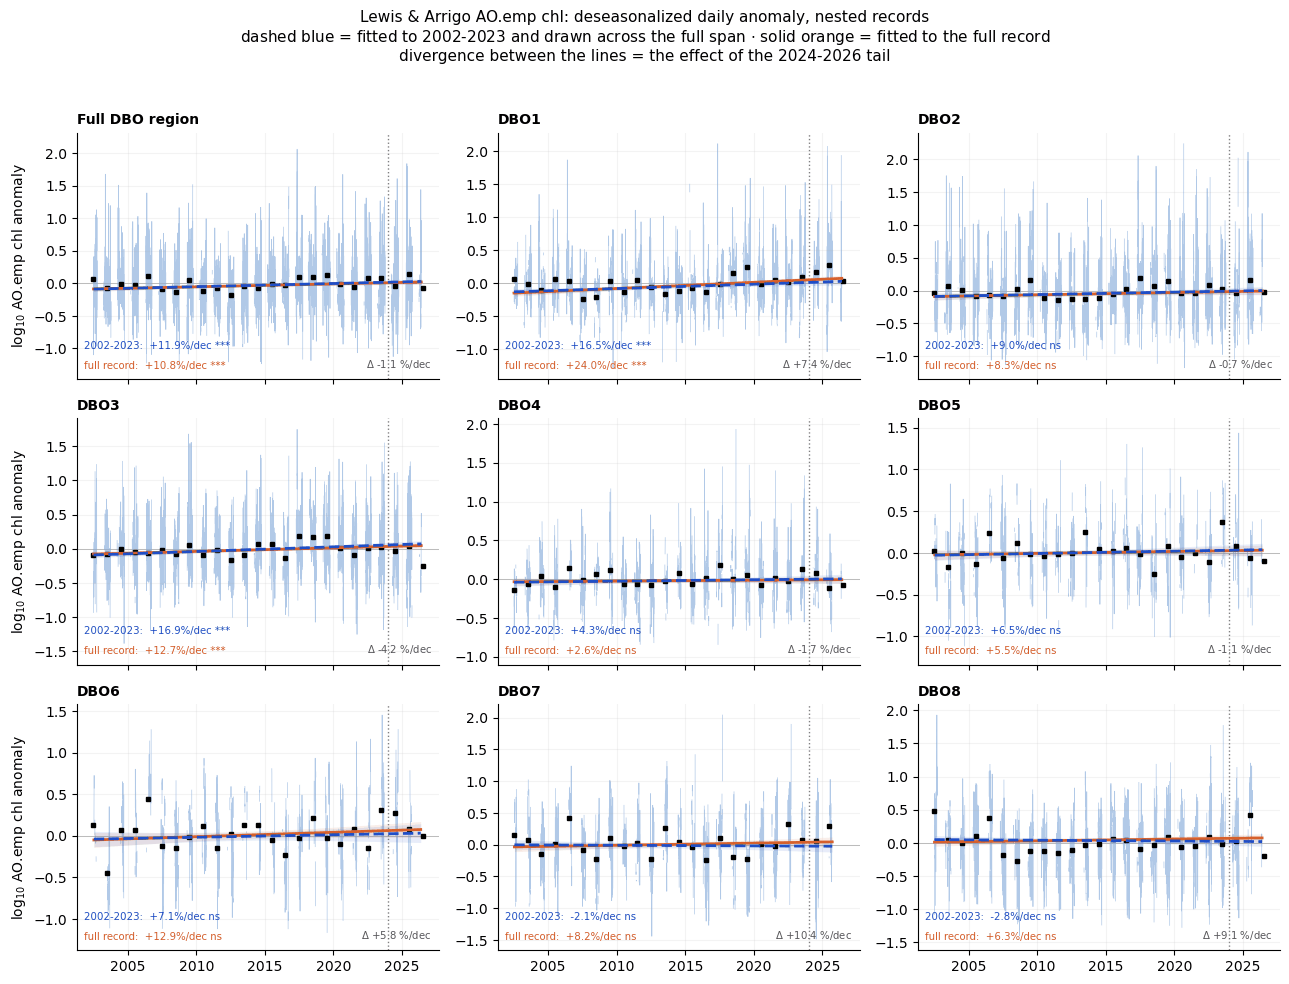


=== chl: 2002-2023 vs full record ===
                 trend<2024 (%/dec)  p<2024  trend_full (%/dec)  p_full  \
box                                                                       
Full DBO region              11.915   0.000              10.844   0.000   
DBO1                         16.545   0.000              23.955   0.000   
DBO2                          9.000   0.071               8.267   0.060   
DBO3                         16.927   0.000              12.709   0.000   
DBO4                          4.270   0.349               2.602   0.508   
DBO5                          6.519   0.299               5.466   0.301   
DBO6                          7.132   0.468              12.895   0.151   
DBO7                         -2.142   0.788               8.218   0.257   
DBO8                         -2.770   0.615               6.294   0.244   

                  delta   flip  
box                             
Full DBO region  -1.071  False  
DBO1              7.410  False  
DBO

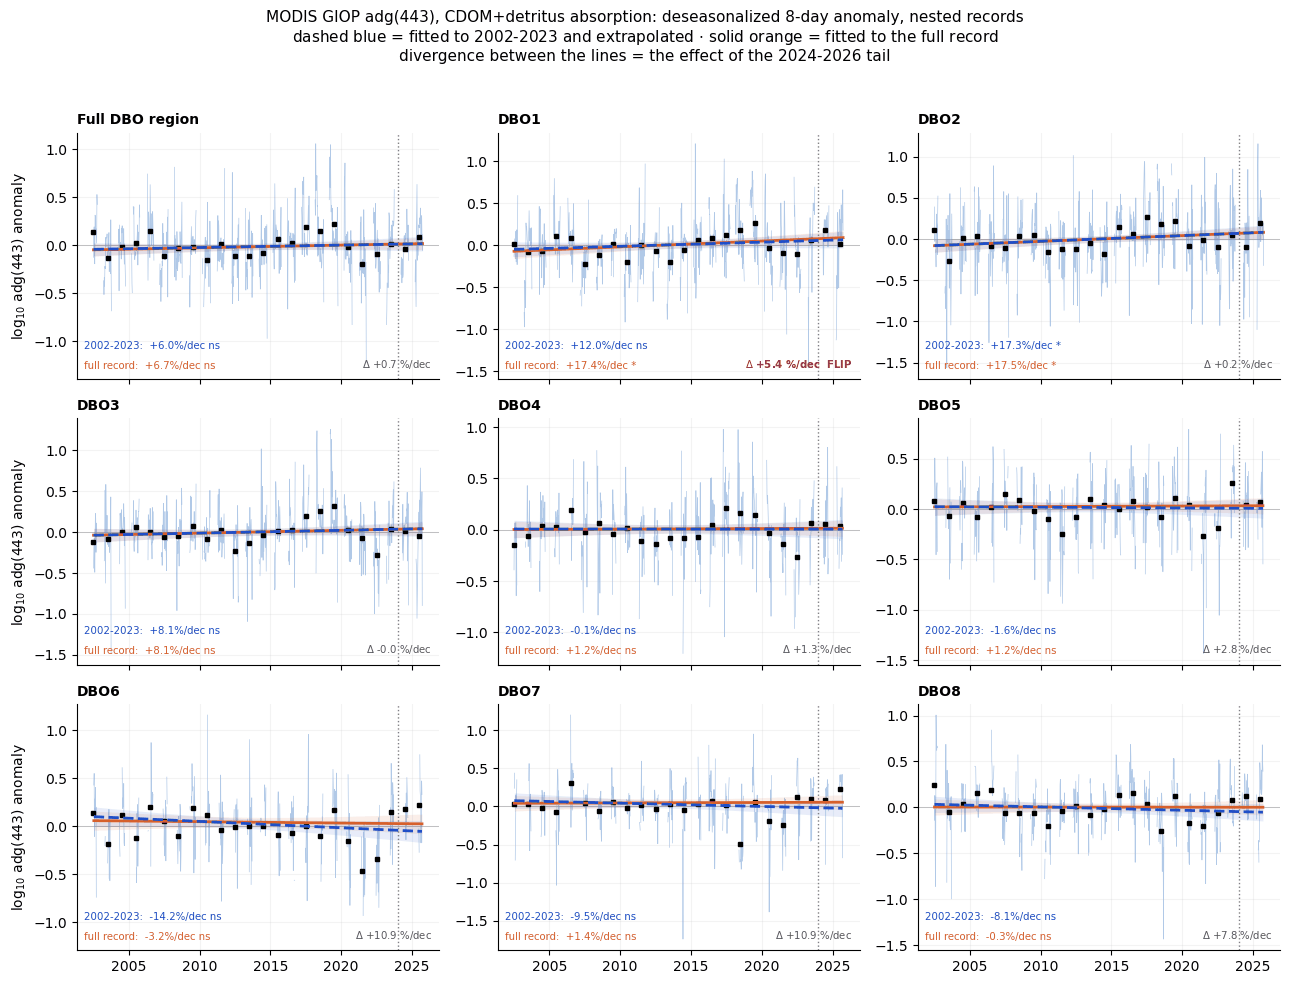


=== adg: 2002-2023 vs full record ===
                 trend<2024 (%/dec)  p<2024  trend_full (%/dec)  p_full  \
box                                                                       
Full DBO region               6.001   0.318               6.698   0.207   
DBO1                         11.989   0.128              17.412   0.016   
DBO2                         17.311   0.027              17.475   0.014   
DBO3                          8.149   0.218               8.115   0.190   
DBO4                         -0.105   0.982               1.239   0.841   
DBO5                         -1.589   0.839               1.237   0.856   
DBO6                        -14.174   0.107              -3.243   0.700   
DBO7                         -9.478   0.265               1.382   0.865   
DBO8                         -8.129   0.282              -0.282   0.972   

                  delta   flip  
box                             
Full DBO region   0.697  False  
DBO1              5.422   True  
DBO

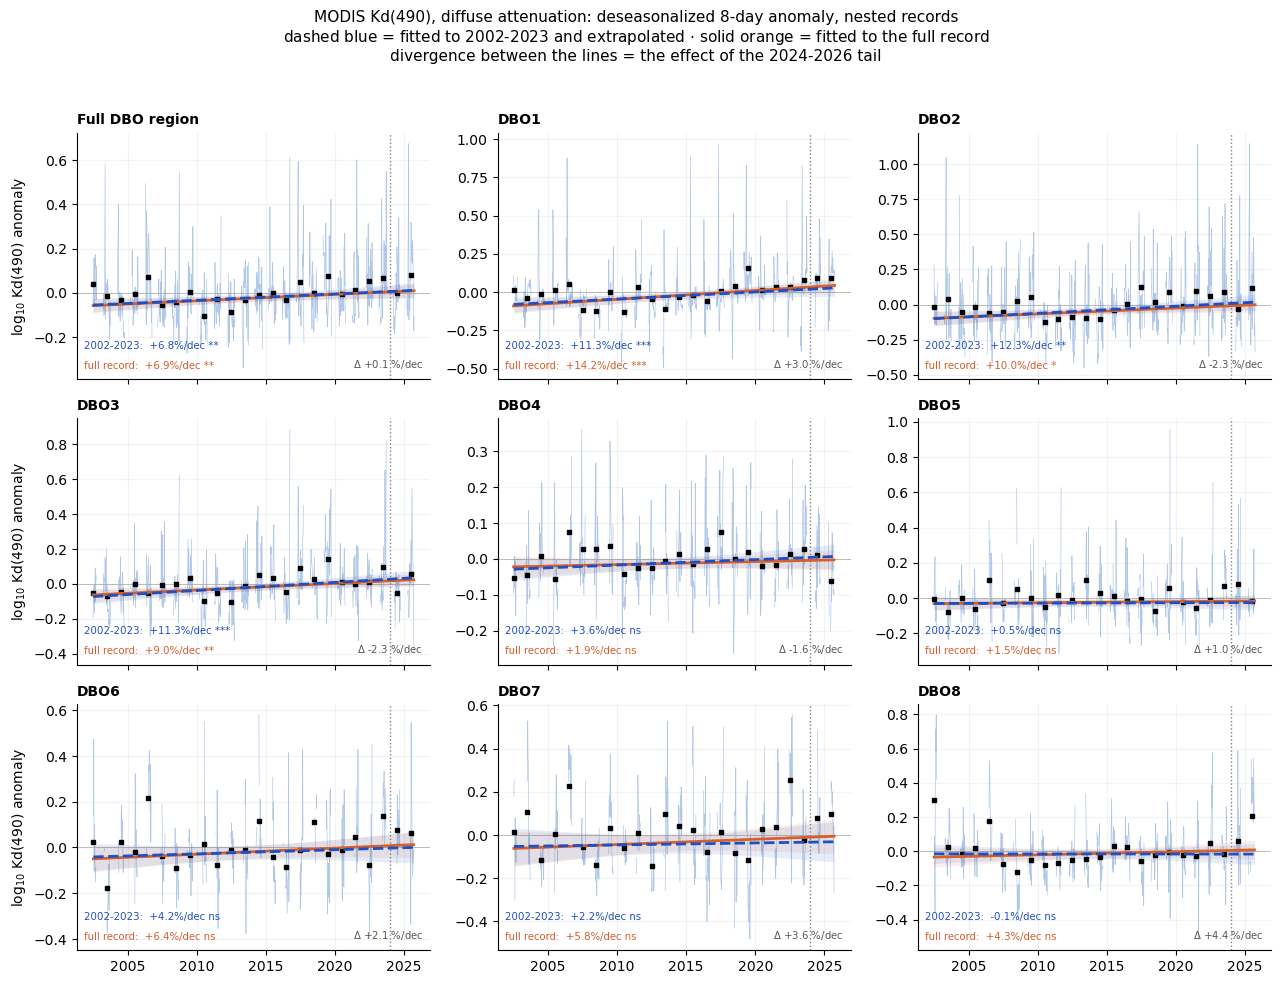


=== kd490: 2002-2023 vs full record ===
                 trend<2024 (%/dec)  p<2024  trend_full (%/dec)  p_full  \
box                                                                       
Full DBO region               6.808   0.006               6.920   0.002   
DBO1                         11.252   0.000              14.204   0.000   
DBO2                         12.334   0.008              10.008   0.016   
DBO3                         11.259   0.000               8.993   0.002   
DBO4                          3.579   0.175               1.931   0.429   
DBO5                          0.510   0.863               1.488   0.542   
DBO6                          4.221   0.456               6.359   0.185   
DBO7                          2.167   0.782               5.773   0.421   
DBO8                         -0.145   0.972               4.290   0.304   

                 delta   flip  
box                            
Full DBO region  0.112  False  
DBO1             2.952  False  
DBO2 

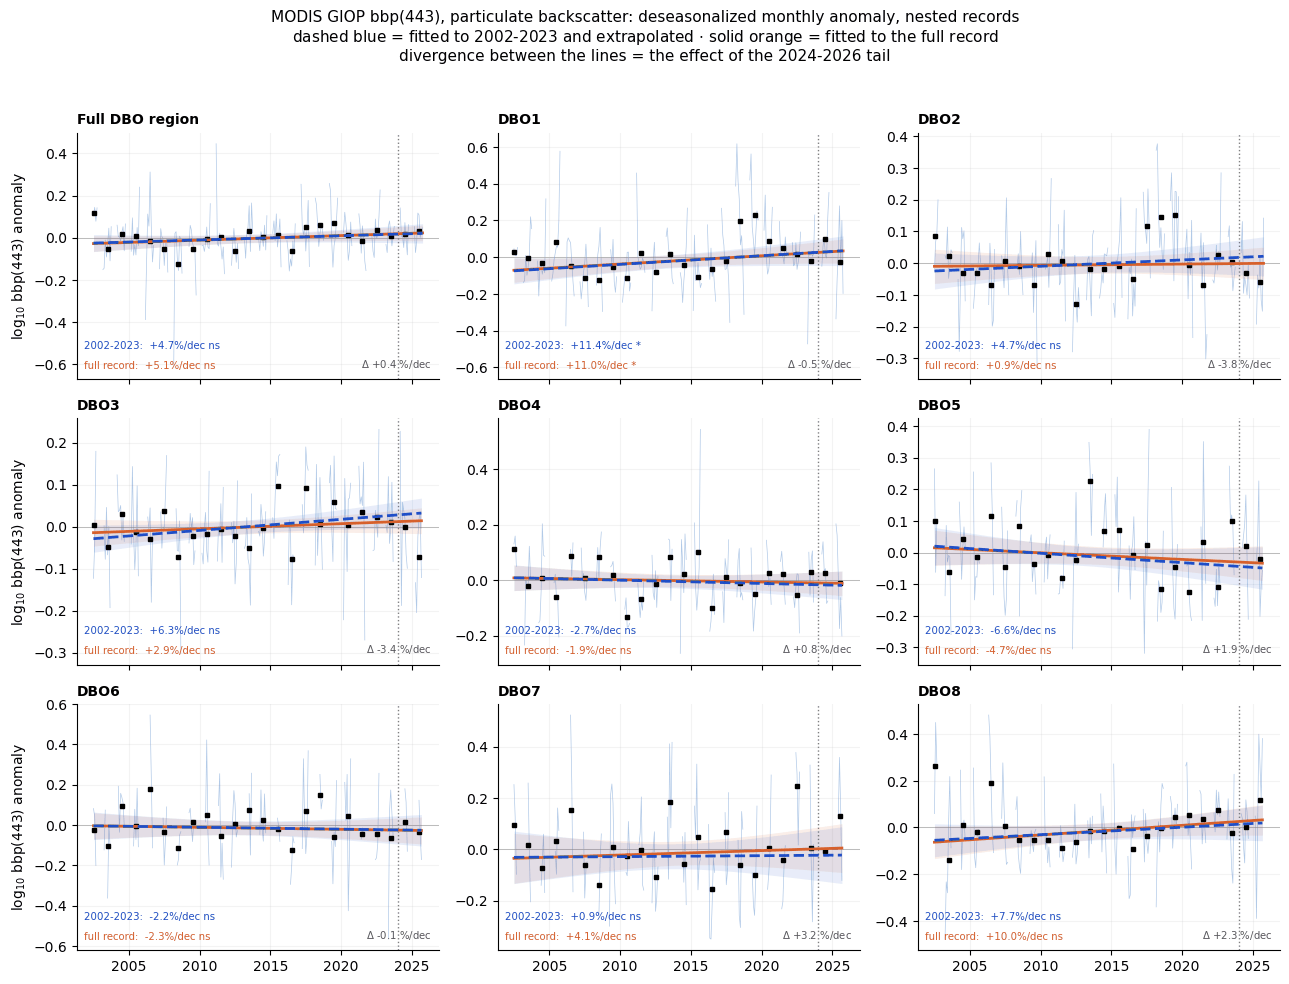


=== bbp: 2002-2023 vs full record ===
                 trend<2024 (%/dec)  p<2024  trend_full (%/dec)  p_full  \
box                                                                       
Full DBO region               4.666   0.154               5.113   0.070   
DBO1                         11.418   0.048              10.959   0.027   
DBO2                          4.684   0.331               0.931   0.828   
DBO3                          6.251   0.055               2.861   0.311   
DBO4                         -2.687   0.470              -1.923   0.593   
DBO5                         -6.619   0.249              -4.718   0.322   
DBO6                         -2.151   0.684              -2.264   0.629   
DBO7                          0.864   0.923               4.058   0.634   
DBO8                          7.656   0.249               9.959   0.102   

                 delta   flip  
box                            
Full DBO region  0.447  False  
DBO1            -0.460  False  
DBO2   

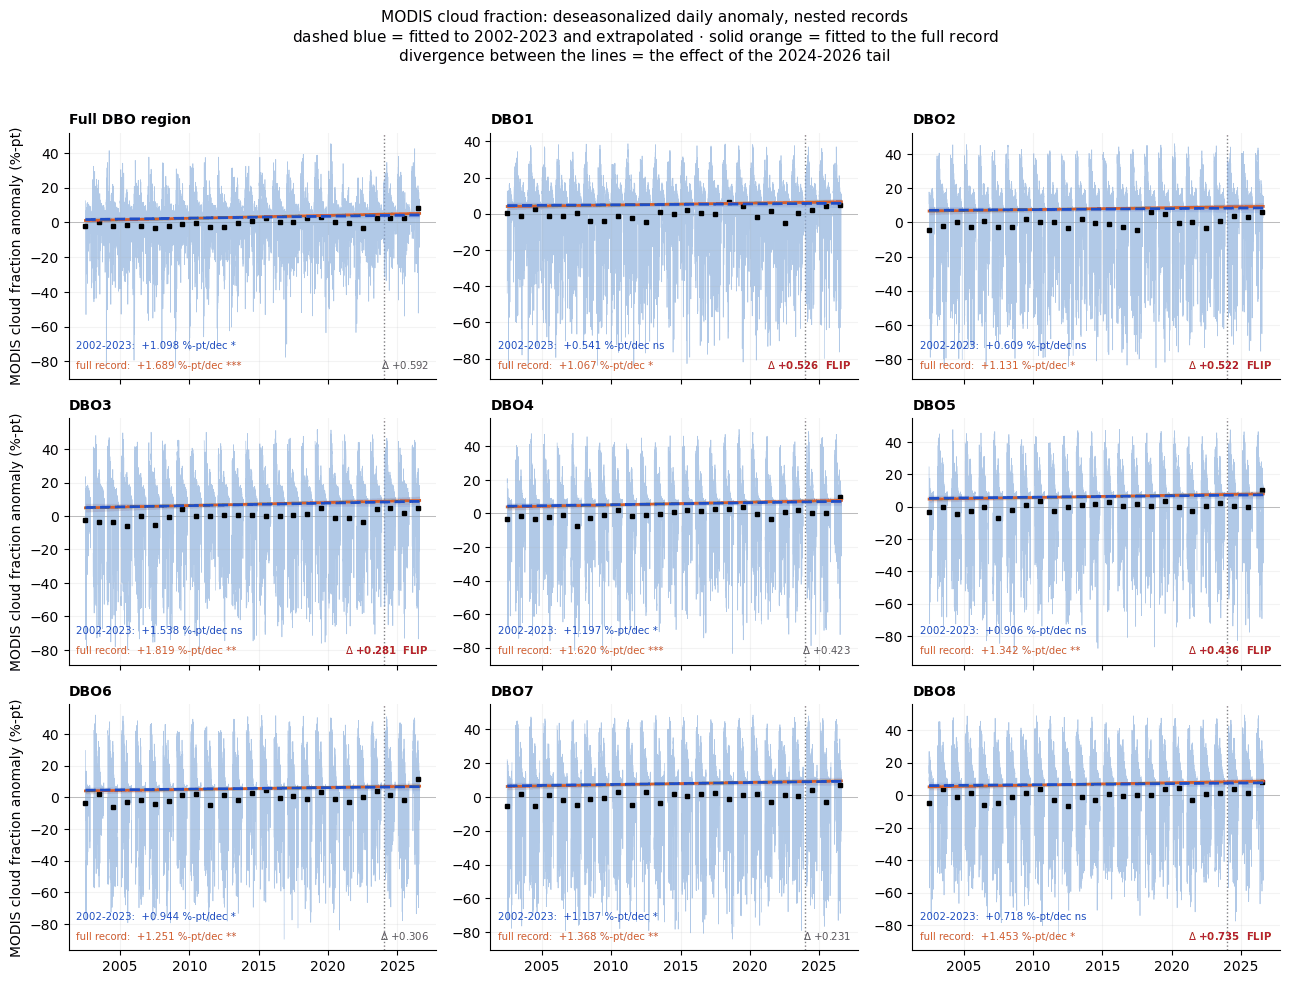


=== cloudfrac: 2002-2023 vs full record ===
                 trend<2024 (%-pt/dec)  p<2024  trend_full (%-pt/dec)  p_full  \
box                                                                             
Full DBO region                  1.098   0.012                  1.689   0.000   
DBO1                             0.541   0.297                  1.067   0.013   
DBO2                             0.609   0.330                  1.131   0.032   
DBO3                             1.538   0.067                  1.819   0.008   
DBO4                             1.197   0.027                  1.620   0.001   
DBO5                             0.906   0.099                  1.342   0.006   
DBO6                             0.944   0.039                  1.251   0.003   
DBO7                             1.137   0.048                  1.368   0.007   
DBO8                             0.718   0.333                  1.453   0.024   

                 delta   flip  
box                            

In [7]:
nested_tables = {}

def nested_figure(key):
    p = PRODUCTS_N[key]; panels = series_nested[key]
    log = p["kind"] == "log"; minn = p["minn"]
    names = [REGION] + sorted(n for n in panels if n.upper().startswith("DBO"))
    ncol = 3; nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True)
    axes = np.atleast_1d(axes).ravel(); rows = []

    for ax, name in zip(axes, names):
        if log:
            t, dec, anom = deseasonalize_log10(panels[name], p["cadence"])
        else:
            t, dec, anom = deseasonalize_linear(panels[name])
        ax.plot(dec, anom, "-", color="#7ea6d8", lw=0.5, alpha=0.6, zorder=1)
        dfa = pd.DataFrame({"y": anom, "yr": np.asarray(pd.to_datetime(t).year, int)}).dropna()
        if len(dfa):
            ga = dfa.groupby("yr")["y"].mean()
            ax.plot(ga.index.values + 0.5, ga.values, "s", color="k", ms=3.0, zorder=3)
        ax.axhline(0, color="0.7", lw=0.6, zorder=0)
        ax.axvline(CUTOFF_N, color="0.5", ls=":", lw=1.0, zorder=0)

        ok = np.isfinite(dec) & np.isfinite(anom)
        if ok.sum() < minn:
            ax.set_title(name, loc="left", fontweight="bold", fontsize=10); continue
        xs = np.linspace(np.nanmin(dec[ok]), np.nanmax(dec[ok]), 200)

        info = {}
        for tag, sel, col, ls in (("full",  ok,                    C_FULL,  "-"),
                                  ("early", ok & (dec < CUTOFF_N), C_EARLY, "--")):
            r = _seg_trend(dec[sel], anom[sel], minn)
            if r is None:
                info[tag] = dict(txt=f"n<{minn}", col="0.6", val=np.nan, p=np.nan); continue
            yp = r["intercept"] + r["slope"] * xs
            band = tdist.ppf(0.975, r["dof"]) * r["line_se"](xs)
            ax.fill_between(xs, yp - band, yp + band, color=col, alpha=0.10, lw=0, zorder=2)
            ax.plot(xs, yp, ls=ls, color=col, lw=2.0, zorder=4)
            if log:
                info[tag] = dict(txt=f"{r['pct']:+.1f}%/dec {_stx(r['p'])}",
                                 col=col, val=r["pct"], p=r["p"])
            else:
                info[tag] = dict(txt=f"{r['per_dec']:+.3f} {p['unit']}/dec {_stx(r['p'])}",
                                 col=col, val=r["per_dec"], p=r["p"])

        d = info["full"]["val"] - info["early"]["val"]
        flip = (np.isfinite(info["full"]["p"]) and np.isfinite(info["early"]["p"])
                and (info["full"]["p"] < 0.05) != (info["early"]["p"] < 0.05))
        rows.append((name, info["early"]["val"], info["early"]["p"],
                     info["full"]["val"], info["full"]["p"], d, flip))

        ax.set_title(name, loc="left", fontweight="bold", fontsize=10)
        ax.text(0.02, 0.115, f"2002-{CUTOFF_N-1}:  {info['early']['txt']}",
                transform=ax.transAxes, fontsize=7.3, color=info["early"]["col"],
                va="bottom", ha="left")
        ax.text(0.02, 0.035, f"full record:  {info['full']['txt']}",
                transform=ax.transAxes, fontsize=7.3, color=info["full"]["col"],
                va="bottom", ha="left")
        if np.isfinite(d):
            dtxt = f"$\\Delta$ {d:+.1f} %/dec" if log else f"$\\Delta$ {d:+.3f}"
            ax.text(0.98, 0.035, dtxt + ("  FLIP" if flip else ""),
                    transform=ax.transAxes, fontsize=7.3,
                    color="#b2182b" if flip else "0.35",
                    fontweight="bold" if flip else "normal", va="bottom", ha="right")
        for spn in ("top", "right"): ax.spines[spn].set_visible(False)
        ax.grid(alpha=0.15)

    for ax in axes[len(names):]: ax.axis("off")
    for ax in axes[::ncol]: ax.set_ylabel(p["ylab"])
    fig.suptitle(f"{p['title']}\n"
                 f"dashed blue = fitted to 2002-{CUTOFF_N-1} and {p['line2']} $\\cdot$ "
                 "solid orange = fitted to the full record\n"
                 "divergence between the lines = the effect of the 2024-2026 tail",
                 fontsize=11, y=1.02)
    plt.tight_layout()
    fig.savefig(OUTDIR / f"{key}_nested_{CUTOFF_N}_noemdash.png", dpi=150, bbox_inches="tight")
    plt.show()

    unit = "%/dec" if log else f"{p['unit']}/dec"
    tbl = pd.DataFrame(rows, columns=["box", f"trend<{CUTOFF_N} ({unit})", f"p<{CUTOFF_N}",
                                      f"trend_full ({unit})", "p_full", "delta", "flip"]
                       ).set_index("box")
    nested_tables[key] = tbl
    print(f"\n=== {key}: 2002-{CUTOFF_N-1} vs full record ===")
    print(tbl.round(3))
    print(f"significance FLIPS: {list(tbl.index[tbl['flip']]) or 'none'}")
    return tbl

for key in ("chl", "adg", "kd490", "bbp", "cloudfrac"):
    if key in series_nested:
        nested_figure(key)

## B1. Fall-only high-chl event days, bar style

Loads the daily per-box chlor_a series the fall-events notebook uses, keeps only event
days on/after DOY 213 (Aug 1), and draws them in the re-do-figs Figure-1 bar style so the
significant fall increases (DBO3-5 on the scorecard) are legible on their own. Event
definition unchanged: a day whose box-mean chl exceeds that box's P90 over the full
record; the threshold is computed on all days, only the counting is fall-only.

In [8]:
PCTL      = 90
SPLIT_DOY = 213           # Aug 1: DOY >= this = "fall"

_C = Path.home() / "modis_ease2_derived.pkl"  # add your path
_K = Path.home() / "modis_ease2_ckpt.pkl"  # add your path
if _C.exists():
    box_ts = pickle.load(open(_C, "rb"))["box_ts"]
    print(f"loaded box_ts from {_C.name}")
elif _K.exists():
    box_rows = pickle.load(open(_K, "rb"))["box_rows"]        # {date: (mean_dict, median_dict)}
    dts = sorted(box_rows)
    t = np.array([np.datetime64(d.isoformat()) for d in dts])
    names0 = sorted(box_rows[dts[0]][0])
    box_ts = {n: {"daily_mean": xr.DataArray(
                      np.array([box_rows[d][0].get(n, np.nan) for d in dts], float),
                      dims="time", coords={"time": t})} for n in names0}
    print(f"rebuilt box_ts from {_K.name} ({len(dts)} days)")
else:
    raise FileNotFoundError("neither modis_ease2_derived.pkl nor modis_ease2_ckpt.pkl in $HOME")

USE  = "daily_mean"
time = pd.to_datetime(box_ts[list(box_ts)[0]][USE]["time"].values)
print(f"{time.min().date()} -> {time.max().date()} | boxes: {list(box_ts)}")

rebuilt box_ts from modis_ease2_ckpt.pkl (8530 days)
2002-07-04 -> 2025-11-30 | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']


In [9]:
# --- fall event counts + trends (scorecard estimator) ---
names = list(box_ts)
M = np.column_stack([box_ts[n][USE].values.astype(float) for n in names])
M[~np.isfinite(M) | (M <= 0)] = np.nan
all_years = np.arange(int(time.year.min()), int(time.year.max()) + 1)

def _lag1e(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def mk(x, y, minn=6):
    v = np.isfinite(x) & np.isfinite(y); x, y = x[v], y[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, intercept=np.nan, p=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1e(y - (sl*x + ic))
    ne = n*(1-phi)/(1+phi) if (abs(phi) < 1 and phi != 0) else n
    p = 2*(1 - norm.cdf(abs(tau/np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    return dict(slope=slope, intercept=intercept, p=p, n=n)

def _pfmt(p):
    if not np.isfinite(p): return "p=n/a"
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"

series_all = {"REGION": np.nanmean(M, axis=1), **{n: M[:, j] for j, n in enumerate(names)}}

fall, rows = {}, []
for key, s in series_all.items():
    ok = np.isfinite(s); sv, tt = s[ok], time[ok]
    p90 = np.nanpercentile(sv, PCTL); ev = sv > p90
    df = pd.DataFrame({"year": tt.year.values[ev], "doy": tt.dayofyear.values[ev]})
    cnt = df[df["doy"] >= SPLIT_DOY].groupby("year").size().reindex(all_years, fill_value=0)
    r = mk(cnt.index.values.astype(float), cnt.values.astype(float))
    fall[key] = dict(cnt=cnt, **r)
    rows.append((key, p90, r["slope"] * 10, r["p"],
                 _stx(r["p"]) if np.isfinite(r["p"]) else "n/a"))

tblf = pd.DataFrame(rows, columns=["series", f"P{PCTL}", "fall ev/dec", "p_MK_AR1", "sig"]
                    ).set_index("series")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print(f"Fall (DOY >= {SPLIT_DOY}) high-chl event-day trends, Theil-Sen + AR(1)-MK:\n")
print(tblf)
tblf.to_csv(OUTDIR / "fall_event_trends.csv")
print("\nscorecard check, fall rows DBO1-5: +0.0 / +1.82 / +2.68 / +0.54 / +0.48 ev/dec")

Fall (DOY >= 213) high-chl event-day trends, Theil-Sen + AR(1)-MK:

         P90  fall ev/dec  p_MK_AR1 sig
series                                 
REGION 2.431        3.583     0.058  ns
DBO1   1.731        0.000     0.120  ns
DBO2   4.354        1.818     0.160  ns
DBO3   2.955        2.679     0.007  **
DBO4   1.730        0.541     0.002  **
DBO5   2.480        0.477     0.002  **
DBO6   3.730        0.000     0.053  ns
DBO7   3.272        0.000     0.857  ns
DBO8   2.750        0.000     0.584  ns

scorecard check, fall rows DBO1-5: +0.0 / +1.82 / +2.68 / +0.54 / +0.48 ev/dec


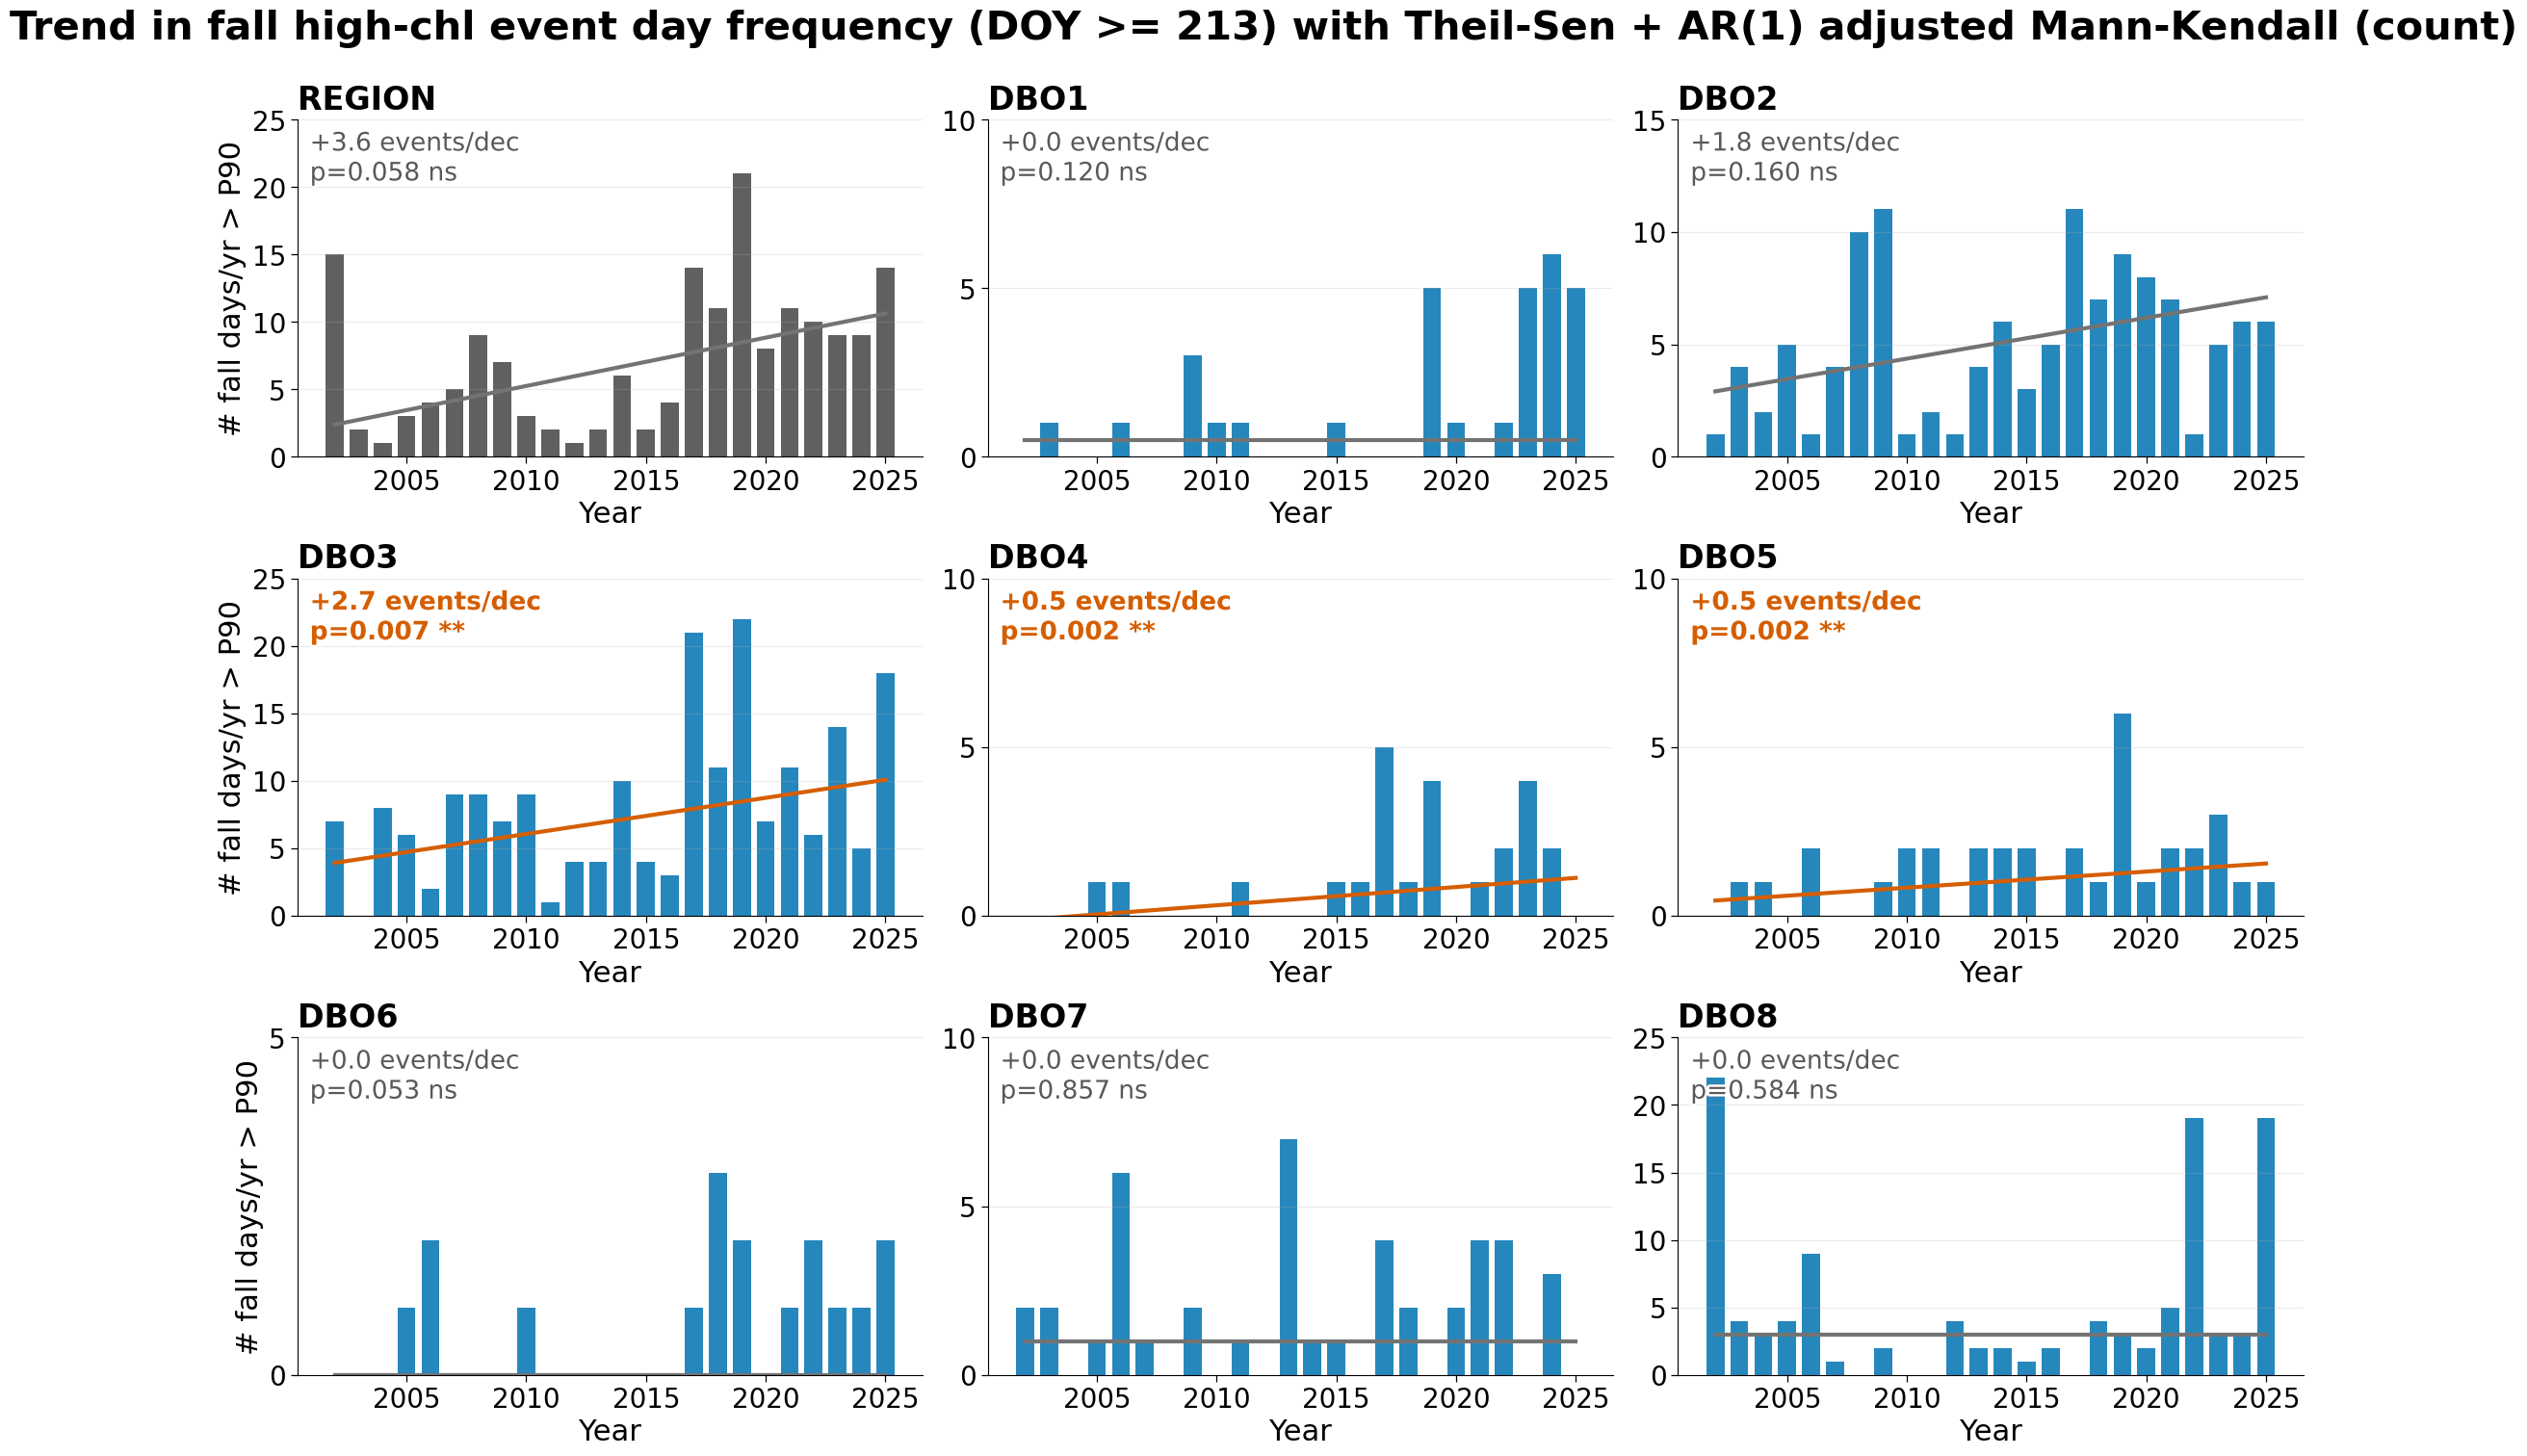

saved -> ~/outputs_remakes/fall_high_chl_events_bars.png


In [10]:
# --- FIGURE: fall event days per year, re-do-figs bar style ---
ACCENT, TRENDLINE = "#0072B2", "#D55E00"       # Okabe-Ito blue / orange (house style)
FS_SUP, FS_TITLE, FS_LAB, FS_TICK, FS_STAT = 30, 24, 22, 20, 19

keys = list(series_all)
fig, axes = plt.subplots(3, 3, figsize=(22, 15), sharex=True)
axes = axes.ravel()
for ax, key in zip(axes, keys):
    r = fall[key]; cnt = r["cnt"]
    ax.bar(cnt.index.values, cnt.values,
           color=("#444444" if key == "REGION" else ACCENT), alpha=0.85, width=0.75)
    sig = np.isfinite(r["p"]) and r["p"] < 0.05
    if np.isfinite(r["slope"]):
        ax.plot(cnt.index.values, r["intercept"] + r["slope"] * cnt.index.values, "-",
                color=(TRENDLINE if sig else "0.45"), lw=3.0, zorder=3)

    ax.set_title(key, fontsize=FS_TITLE, loc="left", fontweight="bold", pad=8)
    ax.text(0.02, 0.965, f"{r['slope']*10:+.1f} events/dec\n{_pfmt(r['p'])} {_stx(r['p'])}",
            transform=ax.transAxes, ha="left", va="top", fontsize=FS_STAT,
            color=(TRENDLINE if sig else "0.35"), fontweight=("bold" if sig else "normal"),
            linespacing=1.25,
            path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=6)

    top = max(5.0, 5.0 * np.ceil(np.nanmax(cnt.values) * 1.12 / 5.0))
    ax.set_ylim(0, top)
    ax.yaxis.set_major_locator(MultipleLocator(5))
    ax.tick_params(axis="both", labelsize=FS_TICK, length=5, width=0.9, labelbottom=True)
    ax.grid(alpha=0.25, axis="y")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

for ax in axes[len(keys):]: ax.axis("off")
for ax in axes[::3]: ax.set_ylabel(f"# fall days/yr > P{PCTL}", fontsize=FS_LAB)
for ax in axes: ax.set_xlabel("Year", fontsize=FS_LAB)
fig.suptitle(f"Trend in fall high-chl event day frequency (DOY >= {SPLIT_DOY}) "
             "with Theil-Sen + AR(1) adjusted Mann-Kendall (count)",
             fontsize=FS_SUP, y=1.005, fontweight="bold")
plt.tight_layout()
fig.savefig(OUTDIR / "fall_high_chl_events_bars.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved ->", OUTDIR / "fall_high_chl_events_bars.png")

rebuilt sea-ice box_ts from ssmi_seaice_ckpt.pkl (16802 days)


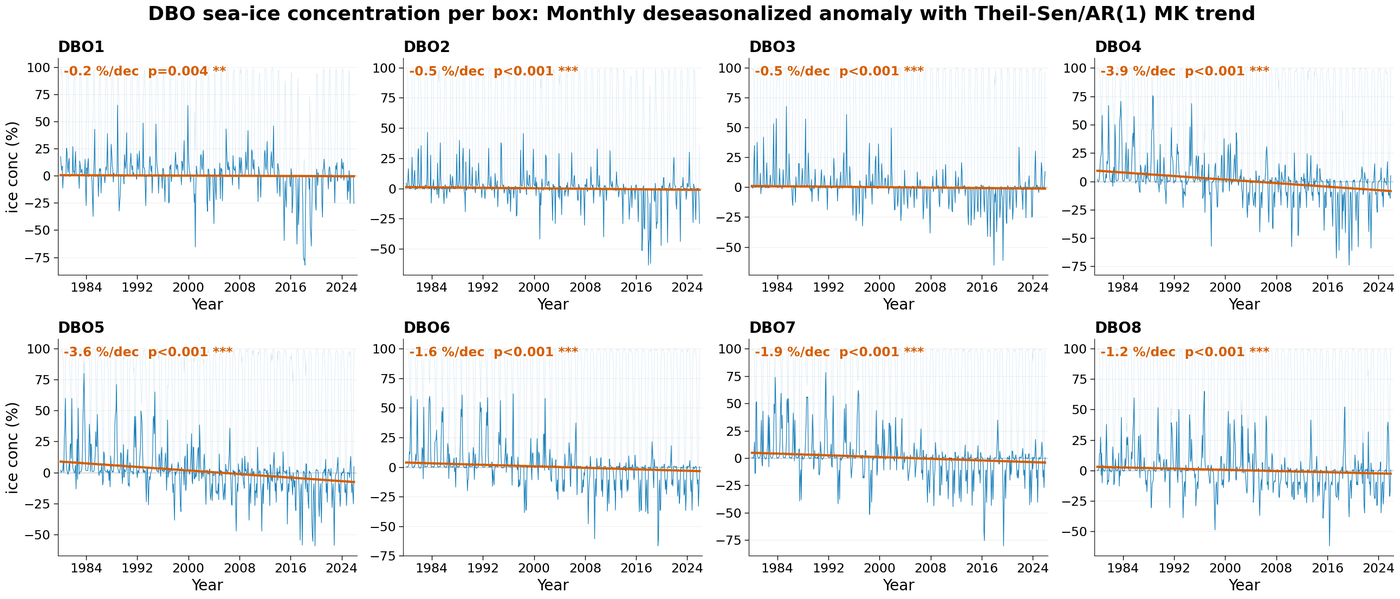

saved -> seaice_conc_perbox_bigfont.png


In [19]:
# === BIGFONT sea-ice concentration per box, house style ==================================
# SELF-LOADING: reads the sea-ice series straight from the ssmi-seaice checkpoints in $HOME,
# into its own variable (ice_box_ts) so it cannot collide with this notebook's chl box_ts.
# Stats identical to ssmi-seaice section 9 (Theil-Sen + AR(1)-adjusted Mann-Kendall).
import pickle
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
from scipy.stats import theilslopes, kendalltau, norm

# ---- load sea-ice box series ------------------------------------------------
_ICE_CACHE = Path.home() / "ssmi_seaice_products.pkl"  # add your path
_ICE_CKPT  = Path.home() / "ssmi_seaice_ckpt.pkl"  # add your path
if _ICE_CACHE.exists():
    _obj = pickle.load(open(_ICE_CACHE, "rb"))["box_ts"]
    def _da(o):
        if isinstance(o, xr.DataArray): return o
        if isinstance(o, dict):
            for k in ("daily_mean", "mean", "value"):
                if k in o: return _da(o[k])
            return _da(next(iter(o.values())))
        return o[list(o.data_vars)[0]]
    ice_box_ts = {n: _da(v) for n, v in _obj.items()}
    print(f"loaded sea-ice box_ts from {_ICE_CACHE.name}")
elif _ICE_CKPT.exists():
    _ck = pickle.load(open(_ICE_CKPT, "rb"))
    _rows = _ck["box_rows"]
    _dts = sorted(_rows); _tc = np.array([np.datetime64(d.isoformat()) for d in _dts])
    _names = sorted({n for d in _dts for n in _rows[d]})
    ice_box_ts = {n: xr.DataArray(np.array([_rows[d].get(n, np.nan) for d in _dts], float),
                                  dims="time", coords={"time": _tc}) for n in _names}
    print(f"rebuilt sea-ice box_ts from {_ICE_CKPT.name} ({len(_dts)} days)")
else:
    raise FileNotFoundError("no ~/ssmi_seaice_products.pkl or ~/ssmi_seaice_ckpt.pkl - "
                            "run the ssmi-seaice streaming pass once first")
_vmax = np.nanmax(np.asarray(ice_box_ts[list(ice_box_ts)[0]].values, float))
assert _vmax > 50, f"loaded series max={_vmax:.1f}, not ice concentration in % - wrong pickle?"

# ---- stats (verbatim ssmi-seaice section 9) --------------------------------
def _lag1i(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def mk_ice(x, y, minn=20):
    v = np.isfinite(x) & np.isfinite(y); x, y = x[v], y[v]; n = len(x)
    if n < minn: return dict(slope=np.nan, intercept=np.nan, p=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1i(y - (sl*x + ic))
    ne = n*(1-phi)/(1+phi) if (abs(phi) < 1 and phi != 0) else n
    p = 2*(1 - norm.cdf(abs(tau/np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    return dict(slope=slope, intercept=intercept, p=p, n=n)

def _stars_i(p):
    return ("***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else "ns") if np.isfinite(p) else "n/a"

def _pfmt_i(p):
    if not np.isfinite(p): return "p=n/a"
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"

# ---- figure -----------------------------------------------------------------
RAW_C, ANOM_C, TREND_C, NS_C = "#A8CBE4", "#0072B2", "#D55E00", "0.45"
FS_SUP, FS_TITLE, FS_STAT, FS_LAB, FS_TICK = 26, 20, 17, 20, 17

_names = [n for n in sorted(ice_box_ts) if n.upper().startswith("DBO")]
fig, axes = plt.subplots(2, 4, figsize=(26, 11), sharex=True)
axes = axes.ravel()
for ax, name in zip(axes, _names):
    monthly = ice_box_ts[name].resample(time="1MS").mean(skipna=True)
    moy = monthly["time"].dt.month
    anom = monthly.assign_coords(moy=("time", moy.values)).groupby("moy") - \
           monthly.assign_coords(moy=("time", moy.values)).groupby("moy").mean()
    t = monthly["time"].values
    dt_ = pd.to_datetime(t)
    dec = np.asarray(dt_.year + (dt_.month - 0.5) / 12.0, float)
    r = mk_ice(dec, anom.values)

    ax.plot(t, monthly.values, "-", color=RAW_C, lw=0.5, alpha=0.55, zorder=1)
    ax.plot(t, anom.values, "-", color=ANOM_C, lw=0.9, alpha=0.9, zorder=2)
    ax.axhline(0, color="0.75", lw=0.8, zorder=0)

    sig = np.isfinite(r["p"]) and r["p"] < 0.05
    if np.isfinite(r["slope"]):
        ax.plot(t, r["intercept"] + r["slope"] * dec, "-" if sig else "--",
                color=(TREND_C if sig else NS_C), lw=3.0, zorder=4)

    ax.set_title(name, fontsize=FS_TITLE, loc="left", fontweight="bold", pad=8)
    ax.text(0.02, 0.965, f"{r['slope']*10:+.1f} %/dec  {_pfmt_i(r['p'])} {_stars_i(r['p'])}",
            transform=ax.transAxes, ha="left", va="top", fontsize=FS_STAT,
            color=(TREND_C if sig else "0.3"), fontweight=("bold" if sig else "normal"),
            path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=6)

    ax.grid(alpha=0.2, axis="y")
    ax.tick_params(axis="both", labelsize=FS_TICK, length=6, width=1.0, labelbottom=True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.margins(x=0.01)

for ax in axes[::4]: ax.set_ylabel("ice conc (%)", fontsize=FS_LAB)
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(base=8))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_xlabel("Year", fontsize=FS_LAB)
fig.suptitle("DBO sea-ice concentration per box: Monthly deseasonalized anomaly with Theil-Sen/AR(1) MK trend",
             fontsize=FS_SUP, y=1.0, fontweight="bold")
plt.tight_layout()
fig.savefig("seaice_conc_perbox_bigfont.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved -> seaice_conc_perbox_bigfont.png")



---

# Part C — Fig. 8 chl rows: AO.emp trends and high-chl event metrics per box

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# Put every chl number on Lewis & Arrigo AO.emp

Needs `~/modis_LA_dbo_DAY_v2_ckpt.pkl` from `1_pull_data/01_modis-aoemp-chl-daily.ipynb`.
Nothing here re-streams MODIS — it reads the existing checkpoint.

## The problem

Every chl number in the scorecard is currently **AOReg.emp** (regional inflow/outflow
shelf coefficients), not **AO.emp** (pan-Arctic). That happened because
`01_modis-aoemp-chl-daily.ipynb` §21 reads `_ck["chl_rows"]`, and the v2 checkpoint
stores *both* series:

| key | parameterization | coefficients |
|---|---|---|
| `chl_rows`   | AOReg.emp — regional shelf | `a=0.2391, b=-3.3662, c=1.1085` |
| `chl_rows_e` | **AO.emp — pan-Arctic**    | `a=0.0957, b=-2.7973, c=0.6581` |

So the fix is **one dictionary key**, not a re-run of the stream. The trends will change
— the two parameterizations differ systematically (§13 of that notebook prints the
median AO.emp/AOReg ratio) — so the current +24.7 / +8.8 / +14.4 / +2.5 / +6.1 will all
need replacing.

AO.emp is also the form that was actually validated against DBO in-situ
(N=48, R² 0.495, RMSE 0.395 log₁₀, bias −0.017 log₁₀), so moving to it makes the
validated product and the trended product the same thing.

## What this notebook does

- **Part A** — chl trend per box on AO.emp; AOReg.emp alongside for comparison.
- **Part B** — high-chl event metrics on AO.emp, replacing the three `chlor_a` rows.
- **Part C** — tests whether valid-day count trends (the sampling confound).
- **Part D** — exports rows in the exact form the Fig. 8 scorecard (assembled outside this repository) expects.

Optional: **Part E** re-runs the in-situ validation for AOReg.emp, only useful if you
decide to keep AOReg.emp anywhere.


## Setup

In [ ]:

import pickle, numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import norm

CKPT  = Path.home() / "modis_LA_dbo_DAY_v2_ckpt.pkl"  # add your path
OUT   = Path.home() / "la_aoemp_scorecard_rows.csv"  # add your path
BOXES = [f"DBO{i}" for i in range(1, 9)]
SCORECARD_BOXES = [f"DBO{i}" for i in range(1, 6)]   # the five the poster uses

PCTL      = 90     # high-chl threshold, per box, over its own record
SPLIT_DOY = 213    # ~1 Aug; DOY < this = spring, >= this = fall.
                   # Matches 02_modis-chlor-a-daily-ease2.ipynb. Changing it here without
                   # changing it there makes the rows non-comparable.

ck = pickle.load(open(CKPT, "rb"))
print("checkpoint keys:", sorted(ck.keys()))
assert "chl_rows_e" in ck, "no AO.emp series in this checkpoint — it predates the v2 stream"

def to_frame(rows):
    """{date: {box: chl}} -> daily DataFrame, positive values only."""
    df = pd.DataFrame.from_dict(rows, orient="index").sort_index()
    df.index = pd.to_datetime([str(d) for d in df.index])
    return df.where(df > 0)

chl_ao   = to_frame(ck["chl_rows_e"])   # AO.emp    -- PRIMARY
chl_reg  = to_frame(ck["chl_rows"])     # AOReg.emp -- comparison only

print(f"\nAO.emp    {len(chl_ao):,} days  {chl_ao.index.min().date()} -> {chl_ao.index.max().date()}")
print(f"AOReg.emp {len(chl_reg):,} days")
print("\nvalid days per box (AO.emp):")
print(chl_ao.notna().sum().to_string())

### Statistics

Theil–Sen slope with Mann–Kendall significance, Hamed & Rao (1998) autocorrelation
correction. Self-contained, so this notebook does not depend on the other notebooks'
internals.

**Sanity-check before trusting anything below:** run Part A and compare the AOReg.emp
column against the published table (DBO1 +24.66%/dec, p<0.001; DBO2 +8.78, p=0.048;
DBO3 +14.45, p<0.001). If those do not reproduce, this implementation disagrees with
the original and that must be resolved first.

In [ ]:

def theil_sen(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if len(x) < 4:
        return np.nan
    i, j = np.triu_indices(len(x), k=1)
    dx = x[j] - x[i]
    m = dx != 0
    return np.median((y[j] - y[i])[m] / dx[m])

def mk_ar1(x, y):
    """Theil-Sen slope + Mann-Kendall p with Hamed-Rao AR correction.
    Returns (slope_per_unit_x, p, lag1_rho, n)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    n = len(x)
    if n < 6:
        return np.nan, np.nan, np.nan, n

    slope = theil_sen(x, y)
    resid = y - slope * (x - x.mean())
    resid = resid - resid.mean()
    rho = np.corrcoef(resid[:-1], resid[1:])[0, 1]

    S = np.sum(np.sign(y[None, :] - y[:, None])[np.triu_indices(n, 1)])
    var0 = n * (n - 1) * (2 * n + 5) / 18.0

    lags = np.arange(1, n)
    r = np.array([np.corrcoef(resid[:-k], resid[k:])[0, 1] if n - k > 2 else 0.0 for k in lags])
    r = np.where(np.abs(r) > 1.96 / np.sqrt(n), r, 0.0)      # significant lags only
    infl = 1 + (2.0 / (n * (n - 1) * (n - 2))) * np.sum(
        (n - lags) * (n - lags - 1) * (n - lags - 2) * r)
    var = var0 * max(infl, 1e-6)

    z = (S - np.sign(S)) / np.sqrt(var) if S != 0 else 0.0
    return slope, 2 * (1 - norm.cdf(abs(z))), rho, n

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

def pct_per_decade(dates, values):
    """Multiplicative trend in %/decade: Theil-Sen on log10(chl) vs decimal year."""
    t = np.asarray([d.year + (d.dayofyear - 1) / 365.25 for d in dates], float)
    y = np.log10(np.asarray(values, float))
    slope, p, rho, n = mk_ar1(t, y)
    return (10 ** (slope * 10) - 1) * 100, p, rho, n

---
## Part A — chl trend per box: AO.emp vs AOReg.emp

The AO.emp column is what replaces the scorecard's `Chl a` row.

In [ ]:

rows = []
for b in BOXES:
    for name, frame in [("AO.emp", chl_ao), ("AOReg.emp", chl_reg)]:
        if b not in frame.columns:
            continue
        s = frame[b].dropna()
        tr, p, rho, n = pct_per_decade(s.index, s.values)
        rows.append(dict(box=b, product=name, pct_per_decade=tr,
                         p_AR1=p, sig=stars(p), rho=rho, n_days=n))

chl_trend = pd.DataFrame(rows)
piv = chl_trend.pivot(index="box", columns="product",
                      values=["pct_per_decade", "p_AR1", "sig"])
print(piv.round(3).to_string())

print("\nCHECK -- AOReg.emp should reproduce the published table:")
print("   DBO1 +24.66 (p<0.001) | DBO2 +8.78 (p=0.048) | DBO3 +14.45 (p<0.001)")

---
## Part B — high-chl event metrics on AO.emp

Replaces the three `chlor_a` rows. `event_rate` (events / valid days) is the metric to
trend — a raw count scales with how many valid observations that year had. The count is
kept so you can compare directly against the existing scorecard numbers.

In [ ]:

def event_table(series, split_doy=SPLIT_DOY, pctl=PCTL):
    s = series.dropna()
    if len(s) < 50:
        return None, np.nan
    p90 = np.percentile(s, pctl)
    d = pd.DataFrame({"chl": s})
    d["year"], d["doy"] = d.index.year, d.index.dayofyear
    d["event"]  = d.chl > p90
    d["season"] = np.where(d.doy < split_doy, "spring", "fall")

    out = []
    for keys, g in list(d.groupby(["year", "season"])) + [((y, "all"), g) for y, g in d.groupby("year")]:
        yr, sea = keys
        ev = g[g.event]
        out.append(dict(year=yr, season=sea, n_valid=len(g), n_events=len(ev),
                        event_rate=len(ev) / len(g) if len(g) else np.nan,
                        median_doy=ev.doy.median() if len(ev) else np.nan))
    return pd.DataFrame(out).sort_values(["season", "year"]), p90

tables, p90s = {}, {}
for b in [c for c in BOXES if c in chl_ao.columns]:
    t, p90 = event_table(chl_ao[b])
    if t is not None:
        tables[b], p90s[b] = t, p90
print("AO.emp P90 threshold per box (mg m-3):")
print(pd.Series(p90s).round(2).to_string())

In [ ]:

METRICS = [
    ("event_rate_all",   "all",  "event_rate", "rate/dec"),
    ("event_count_all",  "all",  "n_events",   "ev/dec"),
    ("fall_event_rate",  "fall", "event_rate", "rate/dec"),
    ("fall_event_count", "fall", "n_events",   "ev/dec"),
    ("fall_median_doy",  "fall", "median_doy", "d/dec"),
]

ev_rows = []
for b, t in tables.items():
    for name, season, col, unit in METRICS:
        g = t[t.season == season]
        slope, p, rho, n = mk_ar1(g.year.values, g[col].values)
        ev_rows.append(dict(box=b, metric=name, unit=unit, trend=slope * 10,
                            p_AR1=p, sig=stars(p), rho=rho, n_years=n))
ev = pd.DataFrame(ev_rows)

for name, *_ in METRICS:
    print(f"\n=== {name} ===")
    print(ev[ev.metric == name].set_index("box")[["trend", "p_AR1", "sig", "n_years"]]
            .round(4).to_string())

---
## Part D — export in scorecard form

Prints the `[(trend, p), ...]` tuples ready to paste into `ROWS` in
the Fig. 8 scorecard (assembled outside this repository).

In [ ]:

ao = (chl_trend[(chl_trend["product"] == "AO.emp") & chl_trend.box.isin(SCORECARD_BOXES)]
        .set_index("box").reindex(SCORECARD_BOXES))

print('("BIOLOGY", "Chl a", "MODIS-Aqua · Lewis & Arrigo (2020) AO.emp", "%/dec", "{:+.1f}",')
print("  [" + ", ".join(f"({ao.pct_per_decade[b]:+.1f}, {ao.p_AR1[b]:.4f})" for b in SCORECARD_BOXES) + "]),")

LABELS = {
    "event_count_all":  ('High-chl events (>P90)',       'ev/dec',   '{:+.1f}'),
    "event_rate_all":   ('High-chl event rate',          'rate/dec', '{:+.3f}'),
    "fall_event_count": ('Fall high-chl events',         'ev/dec',   '{:+.1f}'),
    "fall_event_rate":  ('Fall high-chl event rate',     'rate/dec', '{:+.3f}'),
    "fall_median_doy":  ('Fall event date (median DOY)', 'd/dec',    '{:+.1f}'),
}
for metric, (label, unit, fmt) in LABELS.items():
    g = ev[(ev.metric == metric) & ev.box.isin(SCORECARD_BOXES)].set_index("box").reindex(SCORECARD_BOXES)
    src = "MODIS-Aqua · Lewis & Arrigo (2020) AO.emp"
    if "fall" in metric:
        src += " · fall = DOY ≥ 213"
    print(f'\n("BIOLOGY", "{label}", "{src}", "{unit}", "{fmt}",')
    print("  [" + ", ".join(f"({g.trend[b]:+.3f}, {g.p_AR1[b]:.4f})" for b in SCORECARD_BOXES) + "]),")

pd.concat([chl_trend.assign(metric="chl_pct_per_decade"), ev]).to_csv(OUT, index=False)
print(f"\nwrote {OUT}")

### After running

1. Paste the printed tuples over the four BIOLOGY rows in the Fig. 8 scorecard (assembled outside this repository).
2. Update the footnote: AO.emp is now both the trended and the validated product, so it
   can simply read *"Chl: Lewis & Arrigo (2020) AO.emp, validated against DBO in-situ
   (N=48): R² 0.50, RMSE 0.40 log₁₀, bias −0.02 log₁₀."* — drop the "validation pending" line.
3. If you switch counts to rates, the row `unit` changes (`ev/dec` → `rate/dec`) and the
   numbers are no longer events per decade.
4. Re-run `python the Fig. 8 scorecard`.
